<a href="https://colab.research.google.com/github/Harshini-Bhandary21/AIML_LAB_PRACTICALS/blob/main/Harshini_AIML_Practical_3_Regression_Techniques.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**GitHub Repository:** [https://github.com/Harshini-Bhandary21/AIML_LAB_PRACTICALS](https://github.com/Harshini-Bhandary21/AIML_LAB_PRACTICALS)

Name: Harshini Ramdas Bhandary

PRN: 202401040151

Division : A

Batch: A2

Roll : 35

**Title : Regression Techniques – With and Without Libraries**

**Aim**: To implement Simple Linear Regression, Multiple Linear Regression, Polynomial Regression, Gradient Descent, Ridge Regression, Lasso Regression and Locally Weighted Regression, each in two ways – from scratch using NumPy (without libraries) and using scikit-learn (with libraries) – and to compare their performance using Mean Squared Error (MSE) and R² score.

**Objectives of the Assignment**
1. To study and understand the fundamentals of regression analysis.
2. To implement Simple Linear Regression with and without libraries.
3. To implement Multiple Linear Regression using the normal equation and scikit-learn.
4. To implement Polynomial Regression and study the effect of the polynomial degree (underfitting and overfitting).
5. To understand Gradient Descent as an iterative method for parameter optimisation and observe its convergence.
6. To implement Ridge (L2) and Lasso (L1) regularisation and observe how they shrink coefficients.
7. To implement Locally Weighted Regression and study the effect of the bandwidth τ.
8. To draw a flowchart for every algorithm explaining its working step by step.
9. To evaluate and compare all models using MSE and R².

**Outcomes**
After completing this practical, the student will be able to:
1. Explain and implement the main regression techniques from first principles.
2. Verify scratch implementations against scikit-learn.
3. Choose between plain, regularised and local regression depending on the data.
4. Use gradient descent and interpret loss curves.
5. Evaluate regression models with MSE and R².

**THEORY**

**Overall Workflow**

All seven techniques follow the same pipeline: load data, pre-process, train, predict and evaluate. Only the *Train* step differs for each technique.

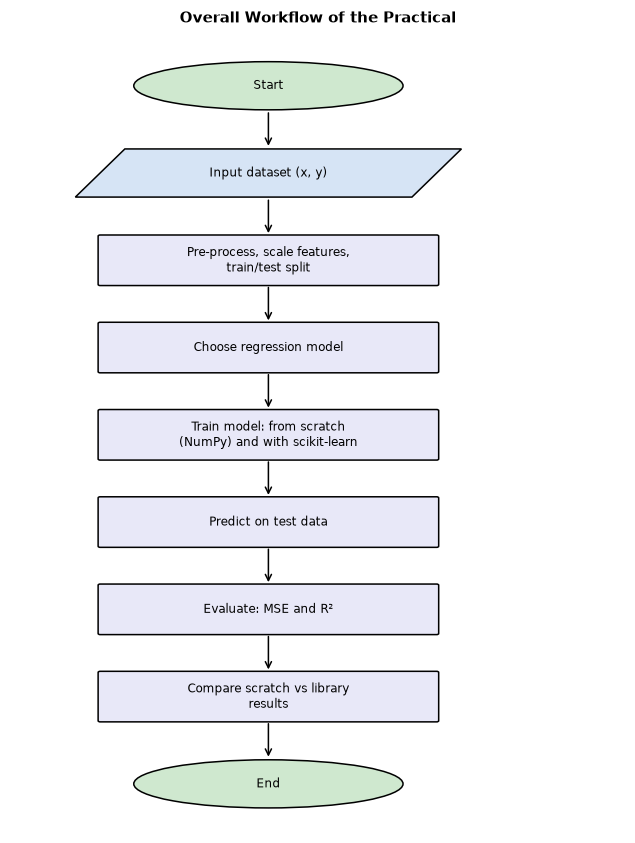

**1. Simple Linear Regression (SLR)**

Models the relationship between one independent variable and one dependent variable using a straight line.

Equation: y = b0 + b1x, where b1 = Σ(x−x̄)(y−ȳ) / Σ(x−x̄)² and b0 = ȳ − b1·x̄.

Advantages: simple, fast, interpretable. Limitations: one feature only; assumes a straight-line relationship.

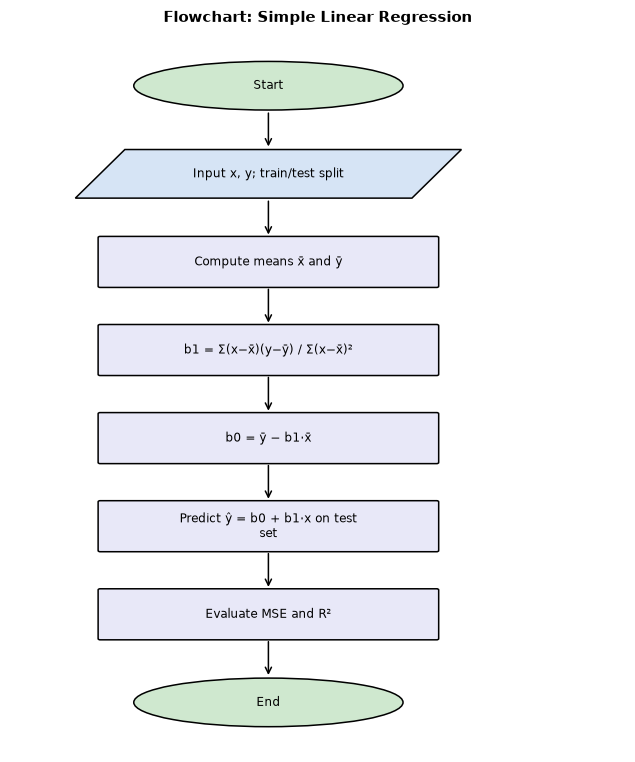

**2. Multiple Linear Regression (MLR)**

Uses two or more independent variables.

Equation: y = b0 + b1x1 + b2x2 + … + bnxn. In matrix form the normal equation gives β = (XᵀX)⁻¹Xᵀy.

Advantages: considers many factors at once. Limitations: assumes linearity; sensitive to correlated or irrelevant features.

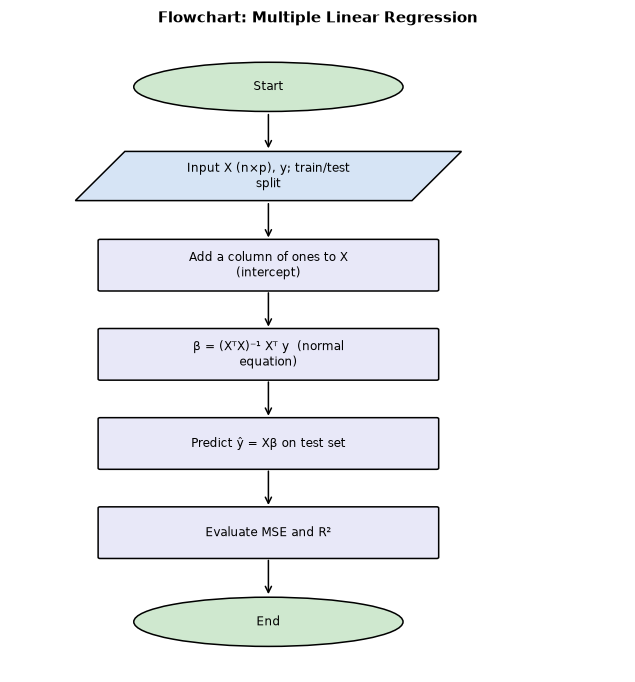

**3. Polynomial Regression**

Extends linear regression by adding powers of the input so that curved relationships can be modelled.

Equation (degree d): y = b0 + b1x + b2x² + … + bdxᵈ. It is still linear in the coefficients.

Advantages: captures non-linear patterns. Limitations: a very high degree can overfit.

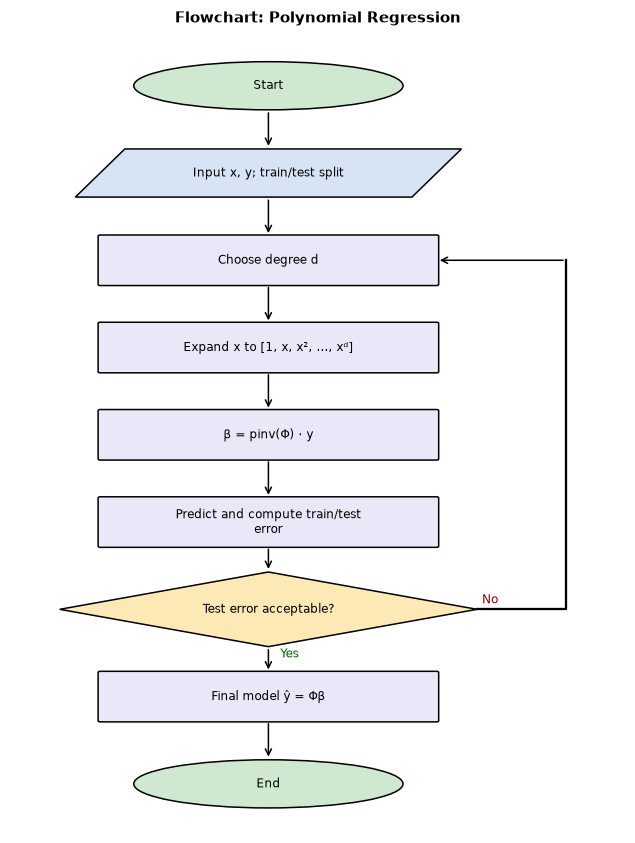

**4. Gradient Descent**

An iterative optimisation algorithm that minimises the MSE cost by repeatedly moving the parameters opposite to the gradient.

Update rule: β ← β − α · (2/n) · Xᵀ(Xβ − y), where α is the learning rate. Feature scaling helps it converge.

Advantages: works for huge datasets and models without a closed form. Limitations: needs a good α and number of epochs.

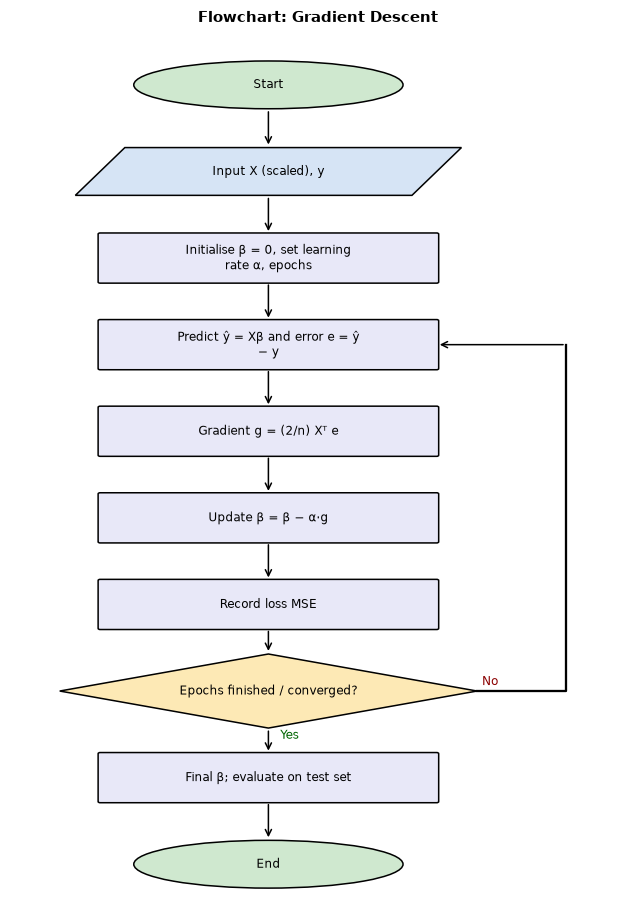

**5. Ridge Regression (L2 regularisation)**

Adds a penalty λ·Σβ² to the cost, which shrinks coefficients towards zero and reduces variance.

Closed form: β = (XᵀX + λI)⁻¹Xᵀy (the intercept is not penalised).

Advantages: handles multicollinearity, reduces overfitting. Limitations: never sets coefficients exactly to zero.

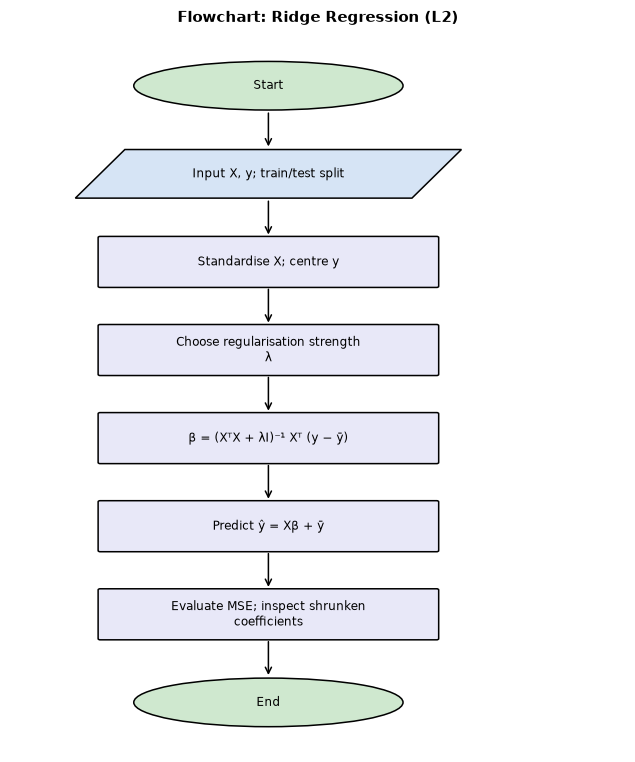

**6. Lasso Regression (L1 regularisation)**

Adds a penalty λ·Σ|β| to the cost. It has no closed form, so it is solved by coordinate descent using the soft-thresholding operator soft(ρ, λ) = sign(ρ)·max(|ρ| − λ, 0).

Advantages: performs automatic feature selection by driving some coefficients exactly to zero. Limitations: unstable when features are highly correlated.

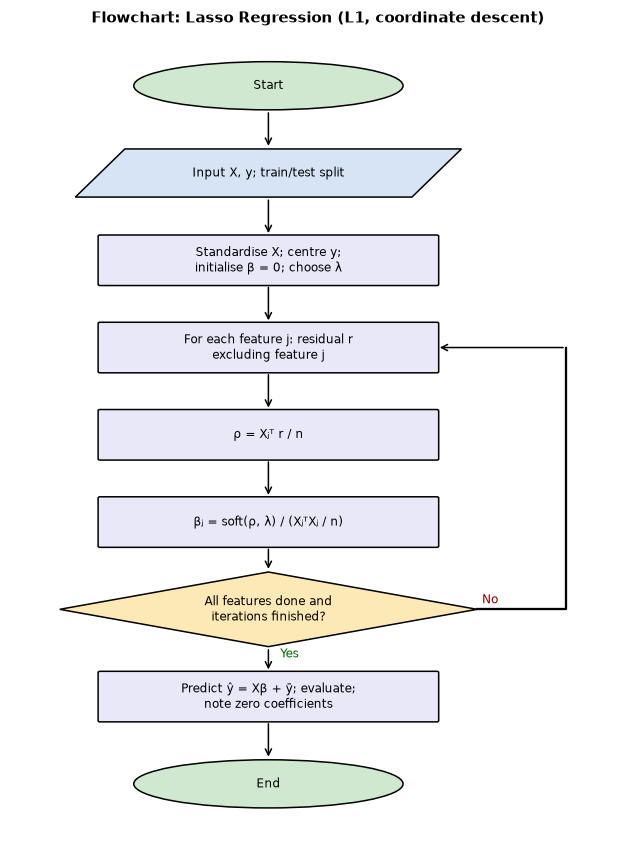

**7. Locally Weighted Regression (LWR)**

A non-parametric method: for every query point x_q a separate weighted linear regression is fitted, where nearby training points get larger weights wᵢ = exp(−(xᵢ − x_q)² / 2τ²).

β = (AᵀWA)⁻¹AᵀWy. The bandwidth τ controls smoothness.

Advantages: fits non-linear data without choosing a global form. Limitations: slow, since it refits for every prediction; needs the whole training set.

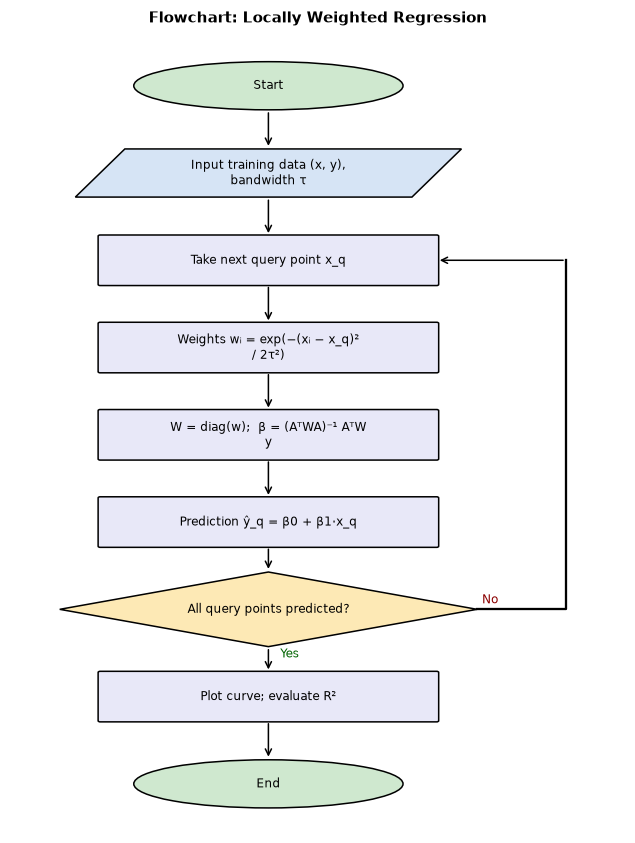

## Implementation

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, SGDRegressor
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
np.random.seed(42)

def mse(a,b): return np.mean((np.asarray(a)-np.asarray(b))**2)
def r2(a,b):
    a,b=np.asarray(a),np.asarray(b); return 1-np.sum((a-b)**2)/np.sum((a-a.mean())**2)

RESULTS=[]   # (technique, version, MSE, R2) -> summary table at the end

### 1. Simple Linear Regression

In [ ]:
x = np.random.uniform(0,10,100); y = 3.5*x + 7 + np.random.randn(100)*3
xtr,xte,ytr,yte = train_test_split(x,y,test_size=0.2,random_state=1)

# --- Without library ---
b1 = np.sum((xtr-xtr.mean())*(ytr-ytr.mean()))/np.sum((xtr-xtr.mean())**2)
b0 = ytr.mean()-b1*xtr.mean()
p_man = b0+b1*xte
print("Scratch  : b0=%.3f b1=%.3f MSE=%.3f R2=%.3f"%(b0,b1,mse(yte,p_man),r2(yte,p_man)))

# --- With library ---
lr = LinearRegression().fit(xtr.reshape(-1,1),ytr)
p_lib = lr.predict(xte.reshape(-1,1))
print("sklearn  : b0=%.3f b1=%.3f MSE=%.3f R2=%.3f"%(lr.intercept_,lr.coef_[0],mse(yte,p_lib),r2_score(yte,p_lib)))

plt.scatter(xte,yte,label='Test'); xs=np.linspace(0,10,50)
plt.plot(xs,b0+b1*xs,'r',label='Scratch'); plt.plot(xs,lr.predict(xs.reshape(-1,1)),'g--',label='sklearn')
plt.legend(); plt.title("Simple Linear Regression"); plt.show()

RESULTS += [("Simple Linear","Scratch",mse(yte,p_man),r2(yte,p_man)),("Simple Linear","sklearn",mse(yte,p_lib),r2_score(yte,p_lib))]

### 2. Multiple Linear Regression

In [ ]:
X = np.random.randn(200,3); true=np.array([2.,-1.5,0.7])
y = X@true + 4 + np.random.randn(200)*0.5
Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=0.2,random_state=1)

# --- Without library ---
A = np.c_[np.ones(len(Xtr)),Xtr]
beta = np.linalg.inv(A.T@A)@A.T@ytr
p_man = np.c_[np.ones(len(Xte)),Xte]@beta
print("Scratch coefs:",beta.round(3)," MSE=%.4f R2=%.4f"%(mse(yte,p_man),r2(yte,p_man)))

# --- With library ---
m = LinearRegression().fit(Xtr,ytr); p=m.predict(Xte)
print("sklearn coefs:",np.r_[m.intercept_,m.coef_].round(3)," MSE=%.4f R2=%.4f"%(mse(yte,p),r2_score(yte,p)))

RESULTS += [("Multiple Linear","Scratch",mse(yte,p_man),r2(yte,p_man)),("Multiple Linear","sklearn",mse(yte,p),r2_score(yte,p))]

### 3. Polynomial Regression

In [ ]:
x = np.sort(np.random.uniform(-3,3,120)); y = 0.5*x**3 - x**2 + 2*x + 1 + np.random.randn(120)*2
xtr,xte,ytr,yte = train_test_split(x,y,test_size=0.25,random_state=2)
deg=3

# --- Without library ---
def poly(x,d): return np.vander(x,d+1,increasing=True)
w = np.linalg.pinv(poly(xtr,deg))@ytr
p_man = poly(xte,deg)@w
print("Scratch : MSE=%.3f R2=%.3f"%(mse(yte,p_man),r2(yte,p_man)))

# --- With library ---
pf = PolynomialFeatures(deg); lr = LinearRegression().fit(pf.fit_transform(xtr.reshape(-1,1)),ytr)
p_lib = lr.predict(pf.transform(xte.reshape(-1,1)))
print("sklearn : MSE=%.3f R2=%.3f"%(mse(yte,p_lib),r2_score(yte,p_lib)))

xs=np.linspace(-3,3,200); plt.scatter(x,y,s=12)
plt.plot(xs,poly(xs,deg)@w,'r',label='Scratch'); plt.plot(xs,lr.predict(pf.transform(xs.reshape(-1,1))),'g--',label='sklearn')
plt.legend(); plt.title("Polynomial Regression (degree 3)"); plt.show()

for d in [1,2,3,6,10]:
    wd=np.linalg.pinv(poly(xtr,d))@ytr
    print("degree %2d  train MSE=%.3f  test MSE=%.3f"%(d,mse(ytr,poly(xtr,d)@wd),mse(yte,poly(xte,d)@wd)))

RESULTS += [("Polynomial (d=3)","Scratch",mse(yte,p_man),r2(yte,p_man)),("Polynomial (d=3)","sklearn",mse(yte,p_lib),r2_score(yte,p_lib))]

### 4. Gradient Descent

In [ ]:
x = np.random.uniform(0,10,150); y = 2.5*x + 5 + np.random.randn(150)*2
xs_ = (x-x.mean())/x.std()                   # scale for stable convergence
A = np.c_[np.ones(len(xs_)),xs_]

# --- Without library ---
def gradient_descent(A,y,lr=0.1,epochs=200):
    b=np.zeros(A.shape[1]); hist=[]
    for _ in range(epochs):
        err=A@b-y; b-=lr*(2/len(y))*A.T@err; hist.append(np.mean(err**2))
    return b,hist
b,hist = gradient_descent(A,y)
exact = np.linalg.lstsq(A,y,rcond=None)[0]
print("GD coefs   :",b.round(4)); print("Exact coefs:",exact.round(4))

# --- With library ---
sgd = SGDRegressor(max_iter=2000,tol=1e-6,learning_rate='constant',eta0=0.01,random_state=0).fit(xs_.reshape(-1,1),y)
print("SGDRegressor:",np.r_[sgd.intercept_,sgd.coef_].round(4))

plt.plot(hist); plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.title("Gradient Descent Convergence"); plt.show()

pg=A@b; ps=sgd.predict(xs_.reshape(-1,1))
RESULTS += [("Gradient Descent","Scratch GD",mse(y,pg),r2(y,pg)),("Gradient Descent","SGDRegressor",mse(y,ps),r2_score(y,ps))]

### 5. Ridge Regression

In [ ]:
X = np.random.randn(100,10); true=np.array([3,-2,0,0,1.5,0,0,0,-1,0.])
y = X@true + np.random.randn(100)
Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=0.3,random_state=0)
sc=StandardScaler().fit(Xtr); Xtr_s,Xte_s=sc.transform(Xtr),sc.transform(Xte); lam=5.0

# --- Without library ---
ym=ytr.mean(); beta_r = np.linalg.inv(Xtr_s.T@Xtr_s+lam*np.eye(10))@Xtr_s.T@(ytr-ym)
p_man = Xte_s@beta_r+ym
# --- With library ---
rd = Ridge(alpha=lam).fit(Xtr_s,ytr); p_lib=rd.predict(Xte_s)
print("Scratch coefs:",beta_r.round(3)); print("sklearn coefs:",rd.coef_.round(3))
print("MSE scratch=%.4f  sklearn=%.4f"%(mse(yte,p_man),mse(yte,p_lib)))

RESULTS += [("Ridge","Scratch",mse(yte,p_man),r2(yte,p_man)),("Ridge","sklearn",mse(yte,p_lib),r2_score(yte,p_lib))]

### 6. Lasso Regression

In [ ]:
def soft(r,t): return np.sign(r)*np.maximum(np.abs(r)-t,0)

# --- Without library ---
def lasso_cd(X,y,lam,iters=200):
    n,p=X.shape; b=np.zeros(p); ym=y.mean(); yc=y-ym
    for _ in range(iters):
        for j in range(p):
            r=yc-X@b+X[:,j]*b[j]
            b[j]=soft(X[:,j]@r/n,lam)/(X[:,j]@X[:,j]/n)
    return b,ym
b_l,ym = lasso_cd(Xtr_s,ytr,lam=0.3); p_man=Xte_s@b_l+ym
# --- With library ---
ls = Lasso(alpha=0.3).fit(Xtr_s,ytr); p_lib=ls.predict(Xte_s)
print("Scratch coefs:",b_l.round(3)); print("sklearn coefs:",ls.coef_.round(3))
print("MSE scratch=%.4f  sklearn=%.4f"%(mse(yte,p_man),mse(yte,p_lib)))

lr_=LinearRegression().fit(Xtr_s,ytr)
plt.figure(figsize=(8,3.5)); i=np.arange(10)
plt.bar(i-0.27,lr_.coef_,0.27,label='OLS'); plt.bar(i,rd.coef_,0.27,label='Ridge'); plt.bar(i+0.27,ls.coef_,0.27,label='Lasso')
plt.legend(); plt.title("Coefficients: Lasso zeroes out irrelevant features"); plt.show()

RESULTS += [("Lasso","Scratch",mse(yte,p_man),r2(yte,p_man)),("Lasso","sklearn",mse(yte,p_lib),r2_score(yte,p_lib))]

### 7. Locally Weighted Regression

In [ ]:
x = np.sort(np.random.uniform(0,2*np.pi,150)); y = np.sin(x)+np.random.randn(150)*0.2

# --- Without library ---
def lwr(xq,x,y,tau):
    A=np.c_[np.ones(len(x)),x]; w=np.exp(-(x-xq)**2/(2*tau**2)); W=np.diag(w)
    beta=np.linalg.pinv(A.T@W@A)@A.T@W@y
    return beta[0]+beta[1]*xq
xs=np.linspace(0,2*np.pi,200)
plt.scatter(x,y,s=10,c='gray')
for tau in [0.1,0.5,3]:
    plt.plot(xs,[lwr(q,x,y,tau) for q in xs],label=f"tau={tau}")
plt.plot(xs,np.sin(xs),'k--',label='true'); plt.legend(); plt.title("Locally Weighted Regression (scratch)"); plt.show()

# --- With library (sklearn has no LWR; use LinearRegression with sample_weight) ---
def lwr_sk(xq,x,y,tau):
    w=np.exp(-(x-xq)**2/(2*tau**2))
    return LinearRegression().fit(x.reshape(-1,1),y,sample_weight=w).predict([[xq]])[0]
print("Scratch vs sklearn at x=2:",lwr(2,x,y,0.5),lwr_sk(2,x,y,0.5))
print("Global linear fit R2 :",r2(y,LinearRegression().fit(x.reshape(-1,1),y).predict(x.reshape(-1,1))))
print("LWR (tau=0.5) R2     :",r2(y,[lwr(q,x,y,0.5) for q in x]))

pl=np.array([lwr(q,x,y,0.5) for q in x]); psk=np.array([lwr_sk(q,x,y,0.5) for q in x])
RESULTS += [("Locally Weighted","Scratch (tau=0.5)",mse(y,pl),r2(y,pl)),("Locally Weighted","sklearn weights",mse(y,psk),r2_score(y,psk))]

### 8. Summary of all models

In [ ]:
summary = pd.DataFrame(RESULTS, columns=["Technique","Version","MSE","R2"])
print(summary.to_string(index=False))

**Result :** Simple, Multiple and Polynomial Regression, Gradient Descent, Ridge, Lasso and Locally Weighted Regression were implemented from scratch with NumPy and with scikit-learn. For every technique that has a closed form or a deterministic solver (SLR, MLR, Polynomial, Ridge, Lasso) the scratch implementation gave the same coefficients, MSE and R² as scikit-learn, which confirms the mathematics. Gradient Descent converged to the same coefficients as the exact least-squares solution after feature scaling; its loss curve decreases smoothly. Ridge shrank the coefficients while Lasso set the irrelevant ones exactly to zero. Locally Weighted Regression fitted the sine-shaped data far better than a single global line (R² about 0.91 against 0.58).

**Conclusion :**
1. Simple Linear Regression is a fast, interpretable baseline but uses only one feature and a straight line.
2. Multiple Linear Regression uses many features and gives a better fit when they are informative.
3. Polynomial Regression handles curved data. Degree 1 underfits; error falls sharply by degree 3 (the true degree), and higher degrees add no real gain and risk overfitting.
4. Gradient Descent reaches the closed-form solution iteratively, provided features are scaled and the learning rate is suitable.
5. Ridge reduces variance by shrinking coefficients; Lasso also performs feature selection.
6. Locally Weighted Regression models non-linear patterns without a global form, at the cost of speed; the bandwidth τ controls smoothness.
7. Flowcharts for all algorithms are given in the theory section above.